# Picking con deposito mobile in una corsia a U

Riproduzione didattica degli algoritmi Basic e ZoomIn di Montemanni, Cervino e Lolli. Eseguire le celle in ordine dalla radice del progetto, dopo `uv sync`. Il modello considera i due contenitori sovrapposti in ogni posizione come due prelievi distinti con la stessa coordinata planare. Le distanze sono euclidee; il deposito si muove nella zona con margine di 0,65 m.
Nel codice, `requested_locations` rappresenta $K$, `qty_by_location` rappresenta $\mathrm{qty}_j$, `picker_distance` rappresenta $L_{\mathrm{picker}}$ e `total_cost` rappresenta $C(p_D)$.


In [1]:
import itertools
from math import dist
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import load_instance, solve_routes
from src.basic import basic_search
from src.comparison import compare
from src.visualization import plot_cost_map, plot_layout
from src.zoomin import zoomin_search

ROOT = (
    Path.cwd()
    if (Path.cwd() / "instances" / "PRP-UW-instances.txt").exists()
    else Path.cwd().parent
)
NAME = "44-(9x4)-10-01"
LIMIT_SECONDS = 0.5  # per candidato; aumentare a 3 o 10 s per confronti più rigorosi
instance = load_instance(NAME, ROOT / "instances" / "PRP-UW-instances.txt")

## 1. Caricare l’ordine

`picklist` indica i prodotti richiesti; `assignment_for_random_storage_policy` associa ogni prodotto al contenitore fisico. Le quantità provengono da `weights`. La geometria segue la numerazione della figura 1 e le coppie sovrapposte condividono una coordinata.


In [2]:
print(
    f"{instance.name}: {instance.layout.count} contenitori, {len(instance.requested_locations)} prelievi, layout {instance.layout.n}×{instance.layout.m}"
)
print(
    f"Q={instance.capacity}, ν={instance.nu:.3f}, limiti deposito={instance.layout.bounds}"
)
picks_table = pd.DataFrame(
    [
        {
            "contenitore": k,
            "x_m": instance.layout.point(k)[0],
            "y_m": instance.layout.point(k)[1],
            "quantità": instance.qty_by_location[k],
        }
        for k in instance.requested_locations
    ]
)
display(picks_table)

44-(9x4)-10-01: 44 contenitori, 10 prelievi, layout 9×4
Q=15, ν=0.333, limiti deposito=(0.65, 10.8, -2.075, 2.075)


,contenitore,x_m,y_m,quantità
0,4,1.35,2.725,2
1,5,2.70,2.725,2
2,16,9.45,2.725,1
3,18,10.80,2.725,1
4,20,11.45,2.025,2
5,22,11.45,0.675,1
6,23,11.45,-0.675,1
7,33,6.75,-2.725,2
8,38,4.05,-2.725,4
9,39,2.70,-2.725,4


## 2. Disegnare il layout

I due numeri di ogni coppia indicano i livelli sovrapposti. Il punto O è l’ingresso; il deposito verde è scelto a mano.


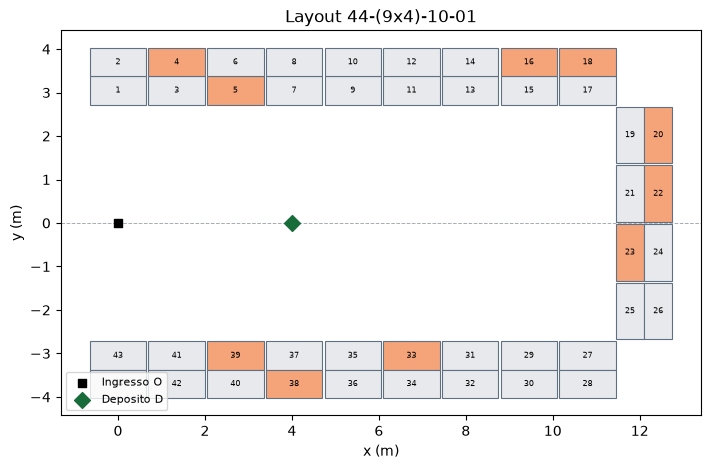

In [3]:
manual_depot = (4.0, 0.0)
plot_layout(instance, depot=manual_depot)
plt.show()

## 3. Risolvere i giri a deposito fisso

Il solver usa `MultipleCircuit` e un carico cumulato che si azzera a ogni partenza dal deposito. Lo stato `OPTIMAL` prova l’ottimalità per il deposito fissato; `FEASIBLE` indica solo una soluzione trovata nel tempo dato.


Stato: OPTIMAL
Giro 1: D → 4 → 5 → 16 → 18 → 20 → 22 → 23 → 33 → D; carico=12/15; distanza=25.905 m
Giro 2: D → 39 → 38 → D; carico=8/15; distanza=7.095 m
Distanza picker totale: 33.00005686553789


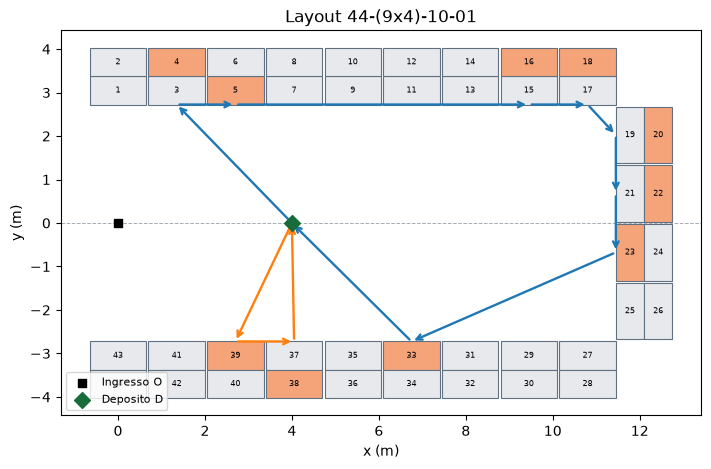

In [4]:
manual_route = solve_routes(instance, manual_depot, LIMIT_SECONDS)
print("Stato:", manual_route.status)
for number, (tour, load) in enumerate(
    zip(manual_route.tours, manual_route.tour_loads), 1
):
    points = [manual_depot] + [instance.layout.point(k) for k in tour] + [manual_depot]
    hand_distance = sum(dist(a, b) for a, b in itertools.pairwise(points))
    print(
        f"Giro {number}: D → {' → '.join(map(str, tour))} → D; carico={load}/{instance.capacity}; distanza={hand_distance:.3f} m"
    )
print("Distanza picker totale:", manual_route.picker_distance)
plot_layout(instance, depot=manual_depot, route=manual_route)
plt.show()

## 4. Basic: scansione uniforme

La griglia è ancorata al limite inferiore di ogni asse. I punti senza soluzione entro il limite rimangono registrati con costo mancante.


Deposito manuale: (4.0, 0.0), costo=34.333
1D migliore: (3.65, 0.0) costo: 34.133 candidati: 11 ottimi: 11
2D migliore: (3.65, -2.075) costo: 31.387 candidati: 55 ottimi: 55


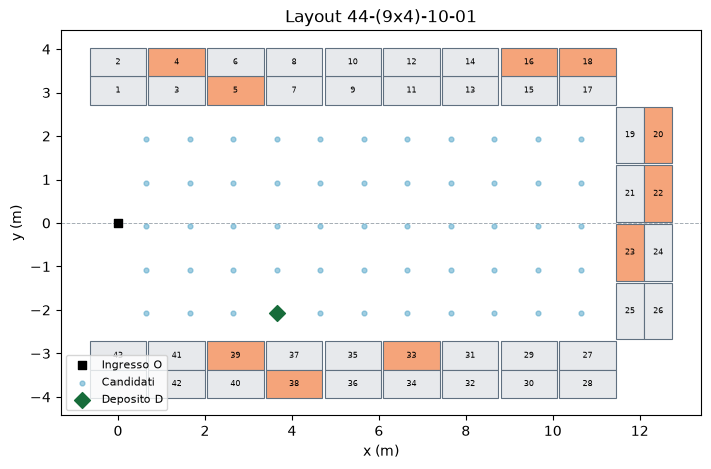

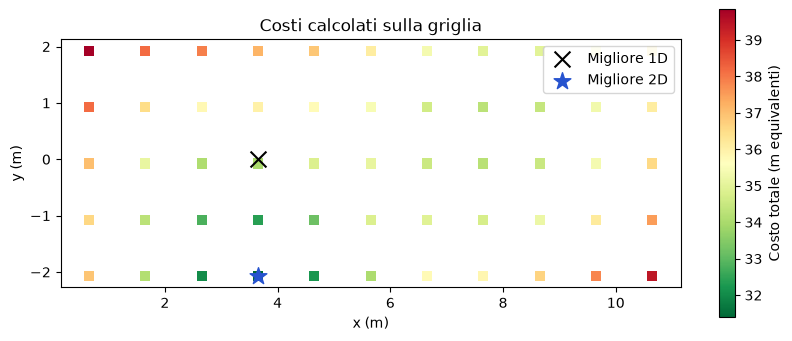

In [5]:
basic_1d = basic_search(instance, step=1.0, mode="1d", limit_seconds=LIMIT_SECONDS)
basic_2d = basic_search(instance, step=1.0, mode="2d", limit_seconds=LIMIT_SECONDS)
assert manual_route.picker_distance is not None
manual_total_cost = manual_route.picker_distance + instance.nu * dist(
    (0, 0), manual_depot
)
print(f"Deposito manuale: {manual_depot}, costo={manual_total_cost:.3f}")
for label, result in (("1D", basic_1d), ("2D", basic_2d)):
    print(
        label,
        "migliore:",
        result.best.depot if result.best else None,
        "costo:",
        round(result.best.total_cost, 3)
        if result.best and result.best.total_cost is not None
        else None,
        "candidati:",
        len(result.candidates),
        "ottimi:",
        result.optimal_count,
    )
plot_layout(
    instance,
    depot=basic_2d.best.depot if basic_2d.best else None,
    candidates=tuple(c.depot for c in basic_2d.candidates),
)
plt.show()
plot_cost_map(
    basic_2d,
    best_1d=basic_1d.best.depot if basic_1d.best else None,
    best_2d=basic_2d.best.depot if basic_2d.best else None,
)
plt.show()

## 5. ZoomIn: restringere la zona

Il primo passo copre tutta l’area. Ogni riquadro seguente è centrato sul migliore della scansione corrente; il migliore globale resta quello con il minor costo tra tutte le iterazioni.


1D arresto: minimum_step migliore: (3.05, 0.0)


,iterazione,passo_m,riquadro,candidati,fattibili,migliore,costo
0,1,2.0,"(0.65, 10.8, -2.075, 2.075)",6,6,"(2.65, 0.0)",34.197437
1,2,0.4,"(0.65, 4.65, -2.0, 2.0)",11,11,"(3.05, 0.0)",34.056583


2D arresto: minimum_step migliore: (3.45, -2.075)


,iterazione,passo_m,riquadro,candidati,fattibili,migliore,costo
0,1,2.0,"(0.65, 10.8, -2.075, 2.075)",18,18,"(2.65, -2.075)",32.024366
1,2,0.4,"(0.65, 4.65, -2.075, -0.075)",66,66,"(3.45, -2.075)",31.404590


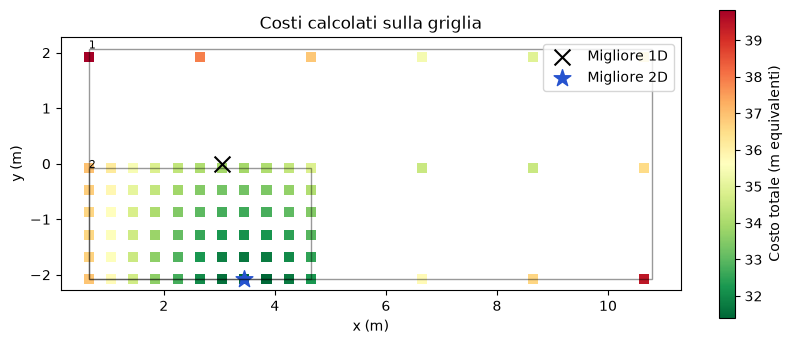

In [6]:
zoom_1d = zoomin_search(
    instance,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    mode="1d",
    limit_seconds=LIMIT_SECONDS,
)
zoom_2d = zoomin_search(
    instance,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    mode="2d",
    limit_seconds=LIMIT_SECONDS,
)
for label, result in (("1D", zoom_1d), ("2D", zoom_2d)):
    print(
        label,
        "arresto:",
        result.stop_reason,
        "migliore:",
        result.best.depot if result.best else None,
    )
    display(
        pd.DataFrame(
            [
                {
                    "iterazione": i,
                    "passo_m": scan.step,
                    "riquadro": scan.bounds,
                    "candidati": len(scan.candidates),
                    "fattibili": scan.feasible_count,
                    "migliore": scan.best.depot if scan.best else None,
                    "costo": scan.best.total_cost if scan.best else None,
                }
                for i, scan in enumerate(result.scans, 1)
            ]
        )
    )
plot_cost_map(
    zoom_2d,
    best_1d=zoom_1d.best.depot if zoom_1d.best else None,
    best_2d=zoom_2d.best.depot if zoom_2d.best else None,
)
plt.show()

## 6. Confrontare i quattro casi

La tabella ricontrolla carichi e decomposizione del costo. Per un confronto con il paper, la tabella 1 riporta circa **34,4** per Basic 1D (`s=1`, 3 s) e **34,3** per ZoomIn 1D (`sM=1,25`, `sm=0,01`, riduzione 5). La tabella 2 riporta **31,3** per ZoomIn 2D (`sM=2`, `sm=0,5`, 20 s). Gli scostamenti dipendono da griglia, limite per candidato, convenzione geometrica e stato del solver; qui i valori sono calcolati con i parametri visibili nella tabella.


In [7]:
# Stessi parametri per entrambe le modalità; compare riesegue le quattro ricerche.
report = compare(
    instance,
    basic_step=1.0,
    initial_step=2.0,
    minimum_step=0.4,
    reduction=5,
    limit_seconds=LIMIT_SECONDS,
)
display(report.table.round(3))
print("Miglioramento 2D su 1D (%):", report.improvement_percent)
for method in ("Basic", "ZoomIn"):
    for mode in ("1d", "2d"):
        result = report.results[f"{method} {mode}"]
        if result.best and result.best.total_cost is not None:
            route = result.best.route
            assert route.picker_distance is not None
            expected_total_cost = route.picker_distance + instance.nu * dist(
                (0, 0), result.best.depot
            )
            assert abs(result.best.total_cost - expected_total_cost) < 1e-9

,depot,tours,picker_distance_m,weighted_forklift_distance_m,total_cost_m,candidates,feasible,optimal,elapsed_s,limit_per_candidate_s,basic_step_m,initial_step_m,minimum_step_m,reduction
method,,,,,,,,,,,,,,
Basic 1d,"(3.65, 0.0)",2,32.916,1.217,34.133,11,11,11,0.371,0.5,1.0,NaN,NaN,NaN
ZoomIn 1d,"(3.05, 0.0)",2,33.040,1.017,34.057,17,17,17,0.761,0.5,NaN,2.0,0.4,5.0
Basic 2d,"(3.65, -2.075)",2,29.987,1.400,31.387,55,55,55,2.211,0.5,1.0,NaN,NaN,NaN
ZoomIn 2d,"(3.45, -2.075)",2,30.063,1.342,31.405,84,84,84,2.939,0.5,NaN,2.0,0.4,5.0


Miglioramento 2D su 1D (%): {'Basic': 8.045609737443003, 'ZoomIn': 7.787021180416032}


### Fonti

- [Montemanni, Cervino e Lolli, *Picking Optimization in U-Shaped Corridors with a Movable Depot*](https://doi.org/10.1007/978-3-031-58113-7_12), figure 1 e tabelle 1–2.
- [Diefenbach et al., definizione della geometria e del dataset](https://doi.org/10.1007/s00291-021-00663-8).
